# Portfolio-opdracht 2: Voorspel verhuuraantallen (CityBike)

<a id="top"></a>

|  |  |
|---|---|
| **Teamnaam (Kaggle)** | ALEX |
| **Competitie** | [Voorspel verhuuraantallen 2026](https://www.kaggle.com/competitions/voorspel-verhuuraantallen-2026) |
| **Datum** | 29-11-2026 |
| **Versie** | v1.0 |

| Teamlid | Studentnummer | Kaggle-gebruikersnaam |
|---|---|---|
| Thomas Schooneman | 25056492 | Thomas-004 |
| Levi Postma | 25042157 | Ikkekoe |
| Alec Veld | 25064185 | Alec Veld |

## Inhoudsopgave

1. [Setup, configuratie en data inladen](#h1)
2. [Opdracht 1: Exploratieve Data Analyse](#h2)
3. [Opdracht 2: Time series feature engineering](#h3)
4. [Opdracht 3: Modelleren](#h4)
5. [Bevindingen](#h5)
6. [Opdracht 4: Conclusie en aanbevelingen](#h6)
7. [Referenties en GenAI-gebruik](#h7)
8. [Inleverchecklist](#h8)

<a id="h1"></a>
# 1. Setup, configuratie en data inladen

[Terug naar boven](#top)

## 1.1 Imports

In [95]:
# Standaardbibliotheken
import warnings
from dataclasses import dataclass, field, replace
from datetime import datetime, date
from pathlib import Path
from html import escape

# Data en visualisatie
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

# Statistiek en tijdreeksen
from scipy import signal, stats
from scipy.fft import rfft, rfftfreq
from scipy.stats import loguniform, randint, iqr
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.seasonal import STL, seasonal_decompose
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller, kpss

# Machine learning
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import (HistGradientBoostingRegressor,
                              RandomForestRegressor)
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

## 1.2 Configuratie

Alle instellingen staan op één plek, zodat het notebook reproduceerbaar is
(vaste `random_state`) en paden/bestandsnamen makkelijk aan te passen zijn.

In [96]:
# Opmaak voor figuren
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 4)

TARGET = "cnt"

warnings.filterwarnings("ignore")

## 1.3 Gen-AI gebruik logboek

In [97]:
AI_LOG = []

def log_ai(titel, model, link, waar, datum=None):
    """Voeg een AI-chat toe aan het logboek.

    titel : titel van de chat
    model : model + versie, bv. "Claude Sonnet 4.5"
    link  : link naar het gesprek
    waar  : waar gebruikt, bv. "§3.2, cel 14"
    datum : standaard vandaag, anders bv. "2026-11-24"
    """
    entry = {
        "Titel van de chat": titel,
        "Model + versie": model,
        "Datum": str(datum or date.today()),
        "Link naar gesprek": link,
        "Waar gebruikt (§ / cel)": waar,
    }
    # Voorkomt dubbele regels als je een cel opnieuw draait
    if entry not in AI_LOG:
        AI_LOG.append(entry)

def show_ai_log():
    """Toon het logboek als tabel met klikbare links."""
    if not AI_LOG:
        print("Nog geen AI-gebruik gelogd.")
        return
    df = pd.DataFrame(AI_LOG)
    df.insert(0, "Prompt nr.", range(1, len(df) + 1))
    df["Link naar gesprek"] = df["Link naar gesprek"].apply(
        lambda u: f'<a href="{escape(u)}" target="_blank">link</a>'
    )
    display(df.style.hide(axis="index"))

# Gebruik

# log_ai(
#     titel="____",
#     model="____",
#     link="____",
#     waar="____"
# )

## 1.4 Data inladen

In [98]:
sample_submission = pd.read_csv("sample_submission.csv")
test_raw = pd.read_csv("test.csv")
train_raw = pd.read_csv("train.csv")

<a id="h2"></a>
# 2. Opdracht 1: Exploratieve Data Analyse

[Terug naar boven](#top)

## 2.1 Datatypes en basisstatistieken

In [99]:
def describe_columns(df):
    """Geef per kolom datatype, ontbrekende waarden en basisstatistieken."""
    summary = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "n_missing": df.isna().sum(),
        "pct_missing": (df.isna().mean() * 100).round(2),
        "n_unique": df.nunique(),
    })
    numeric = df.select_dtypes("number").describe().T
    return summary.join(numeric[["mean", "std", "min", "50%", "max"]])

datasets = {"sample_submission" : sample_submission, "test_raw" : test_raw, "train_raw" : train_raw}

for i, j in datasets.items():
    display(i, describe_columns(j), j.head(), j.shape)

assert set(test_raw) == set(train_raw) - {TARGET}

'sample_submission'

,dtype,n_missing,pct_missing,n_unique,mean,std,min,50%,max
date_hour,object,0,0.0,456,NaN,NaN,NaN,NaN,NaN
cnt,int64,0,0.0,349,413.927632,231.532822,0.0,421.0,799.0


,date_hour,cnt
0,2012-12-01 00:00:00,784
1,2012-12-01 01:00:00,80
2,2012-12-01 02:00:00,605
3,2012-12-01 03:00:00,604
4,2012-12-01 04:00:00,544


(456, 2)

'test_raw'

,dtype,n_missing,pct_missing,n_unique,mean,std,min,50%,max
date_hour,object,0,0.0,456,NaN,NaN,NaN,NaN,NaN
holiday,int64,0,0.0,1,0.000000,0.000000,0.0000,0.0000,0.0000
weathersit,int64,0,0.0,3,1.592105,0.607882,1.0000,2.0000,3.0000
temp,float64,0,0.0,21,0.360132,0.079432,0.1600,0.3600,0.6000
atemp,float64,0,0.0,24,0.363691,0.076354,0.1818,0.3636,0.6212
hum,float64,0,0.0,49,0.714868,0.177732,0.3300,0.7500,1.0000
windspeed,float64,0,0.0,17,0.157639,0.106499,0.0000,0.1343,0.4925


... (2 outputs left out)

'train_raw'

,dtype,n_missing,pct_missing,n_unique,mean,std,min,50%,max
date_hour,object,0,0.0,16637,NaN,NaN,NaN,NaN,NaN
holiday,int64,0,0.0,2,0.028671,0.166885,0.00,0.000,1.0000
weathersit,int64,0,0.0,4,1.415580,0.637298,1.00,1.000,4.0000
temp,float64,0,0.0,50,0.504745,0.192369,0.02,0.520,1.0000
atemp,float64,0,0.0,65,0.482608,0.171557,0.00,0.500,1.0000
hum,float64,0,0.0,89,0.624756,0.193227,0.00,0.620,1.0000
windspeed,float64,0,0.0,30,0.190310,0.121915,0.00,0.194,0.8507
cnt,int64,0,0.0,867,190.477009,182.026755,1.00,143.000,977.0000


,date_hour,holiday,weathersit,temp,atemp,hum,windspeed,cnt
0,2011-01-01 00:00:00,0,1,0.24,0.2879,0.81,0.0,16
1,2011-01-01 01:00:00,0,1,0.22,0.2727,0.80,0.0,40
2,2011-01-01 02:00:00,0,1,0.22,0.2727,0.80,0.0,32
3,2011-01-01 03:00:00,0,1,0.24,0.2879,0.75,0.0,13
4,2011-01-01 04:00:00,0,1,0.24,0.2879,0.75,0.0,1


(16637, 8)

In [100]:
for df in [train_raw, test_raw]:
    df["date_hour"] = pd.to_datetime(
        df["date_hour"],
        errors="coerce",
        format="mixed"
    )

    df["jaar"] = df["date_hour"].dt.year
    df["maand"] = df["date_hour"].dt.month
    df["dag"] = df["date_hour"].dt.day
    df["weekdag"] = df["date_hour"].dt.dayofweek
    df["weekend"] = (df["weekdag"] >= 5).astype(int)

## 2.2 Datakwaliteit en opschoning

Controleer onder meer: dubbele tijdstippen, ontbrekende uren in de reeks,
ontbrekende waarden, onmogelijke waarden (buiten 0-1) en verdachte waarden
(bijv. luchtvochtigheid van precies 0).

In [101]:
def analyseer(df):
    """Rapport: missende waarden, dubbele rijen, onjuiste waarden en outliers."""

    num = df.select_dtypes("number")

    onjuist = pd.Series(0, index=df.columns, dtype="int64")
    onjuist["temp"] = (df["temp"].lt(-20) | df["temp"].gt(45)).sum()

    q1, q3 = num.quantile(0.25), num.quantile(0.75)
    iqr = q3 - q1
    outliers = (num.lt(q1 - 1.5*iqr) | num.gt(q3 + 1.5*iqr)).sum()

    n = len(df)
    rapport = pd.DataFrame({
        "missend": df.isna().sum(),
        "missend_%": (df.isna().mean() * 100).round(2),
        "onjuist": onjuist,
        "onjuist_%": (onjuist / n * 100).round(2),
        "outliers": outliers,
        "outliers_%": (outliers / n * 100).round(2),
    })

    print(f"Dubbele rijen: {df.duplicated().sum()} van {n}")

    return rapport

for df in [train_raw, test_raw]:
    display(analyseer(df))

Dubbele rijen: 0 van 16637


,missend,missend_%,onjuist,onjuist_%,outliers,outliers_%
atemp,0,0.0,0,0.0,0.0,0.00
cnt,0,0.0,0,0.0,486.0,2.92
dag,0,0.0,0,0.0,0.0,0.00
date_hour,0,0.0,0,0.0,NaN,NaN
holiday,0,0.0,0,0.0,477.0,2.87
hum,0,0.0,0,0.0,22.0,0.13
jaar,0,0.0,0,0.0,0.0,0.00
maand,0,0.0,0,0.0,0.0,0.00
temp,0,0.0,0,0.0,0.0,0.00
weathersit,0,0.0,0,0.0,3.0,0.02


Dubbele rijen: 0 van 456


,missend,missend_%,onjuist,onjuist_%,outliers,outliers_%
atemp,0,0.0,0,0.0,4.0,0.88
dag,0,0.0,0,0.0,0.0,0.00
date_hour,0,0.0,0,0.0,NaN,NaN
holiday,0,0.0,0,0.0,0.0,0.00
hum,0,0.0,0,0.0,0.0,0.00
jaar,0,0.0,0,0.0,0.0,0.00
maand,0,0.0,0,0.0,0.0,0.00
temp,0,0.0,0,0.0,7.0,1.54
weathersit,0,0.0,0,0.0,0.0,0.00
weekdag,0,0.0,0,0.0,0.0,0.00


In [102]:
# Zet date_hour om naar datetime
for naam, df in [
    ("train_raw", train_raw),
    ("test_raw", test_raw)
]:
    df["date_hour"] = pd.to_datetime(
        df["date_hour"],
        errors="coerce"
    )

    assert not df.duplicated().any(), (
        f"{naam} bevat dubbele rijen."
    )

    assert not df.isna().any().any(), (
        f"{naam} bevat missende waarden."
    )

    assert "date_hour" in df.columns, (
        f"{naam} bevat de kolom date_hour niet."
    )

    assert pd.api.types.is_datetime64_any_dtype(df["date_hour"]), (
        f"{naam} heeft geen datetime-kolom voor date_hour."
    )

print("Alle controles zijn geslaagd.")

train_clean = train_raw.copy()
test_clean = test_raw.copy()

Alle controles zijn geslaagd.


In [103]:
train_clean = train_clean.set_index("date_hour")
test_clean = test_clean.set_index("date_hour")

assert isinstance(train_clean.index, pd.DatetimeIndex)
assert isinstance(test_clean.index, pd.DatetimeIndex)

print("Beide datasets hebben een datetime-index.")

Beide datasets hebben een datetime-index.


## 2.3 Tijdserie-EDA

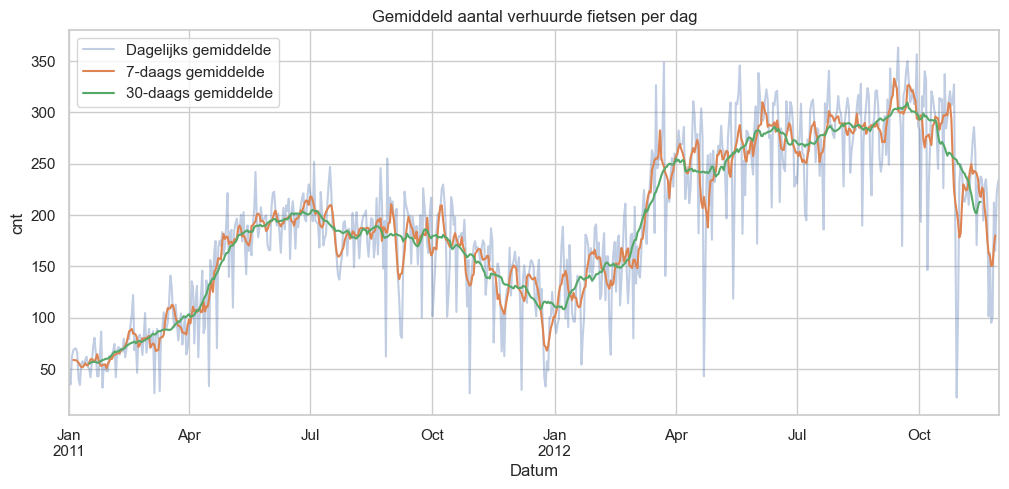

In [104]:
cnt_dagelijks = train_clean["cnt"].resample("D").mean()

fig, ax = plt.subplots(figsize=(12, 5))

cnt_dagelijks.plot(
    ax=ax,
    alpha=0.35,
    label="Dagelijks gemiddelde"
)

cnt_dagelijks.rolling(7, center=True).mean().plot(
    ax=ax,
    label="7-daags gemiddelde"
)

cnt_dagelijks.rolling(30, center=True).mean().plot(
    ax=ax,
    label="30-daags gemiddelde"
)

ax.set(
    title="Gemiddeld aantal verhuurde fietsen per dag",
    xlabel="Datum",
    ylabel="cnt"
)

ax.legend()
plt.show()

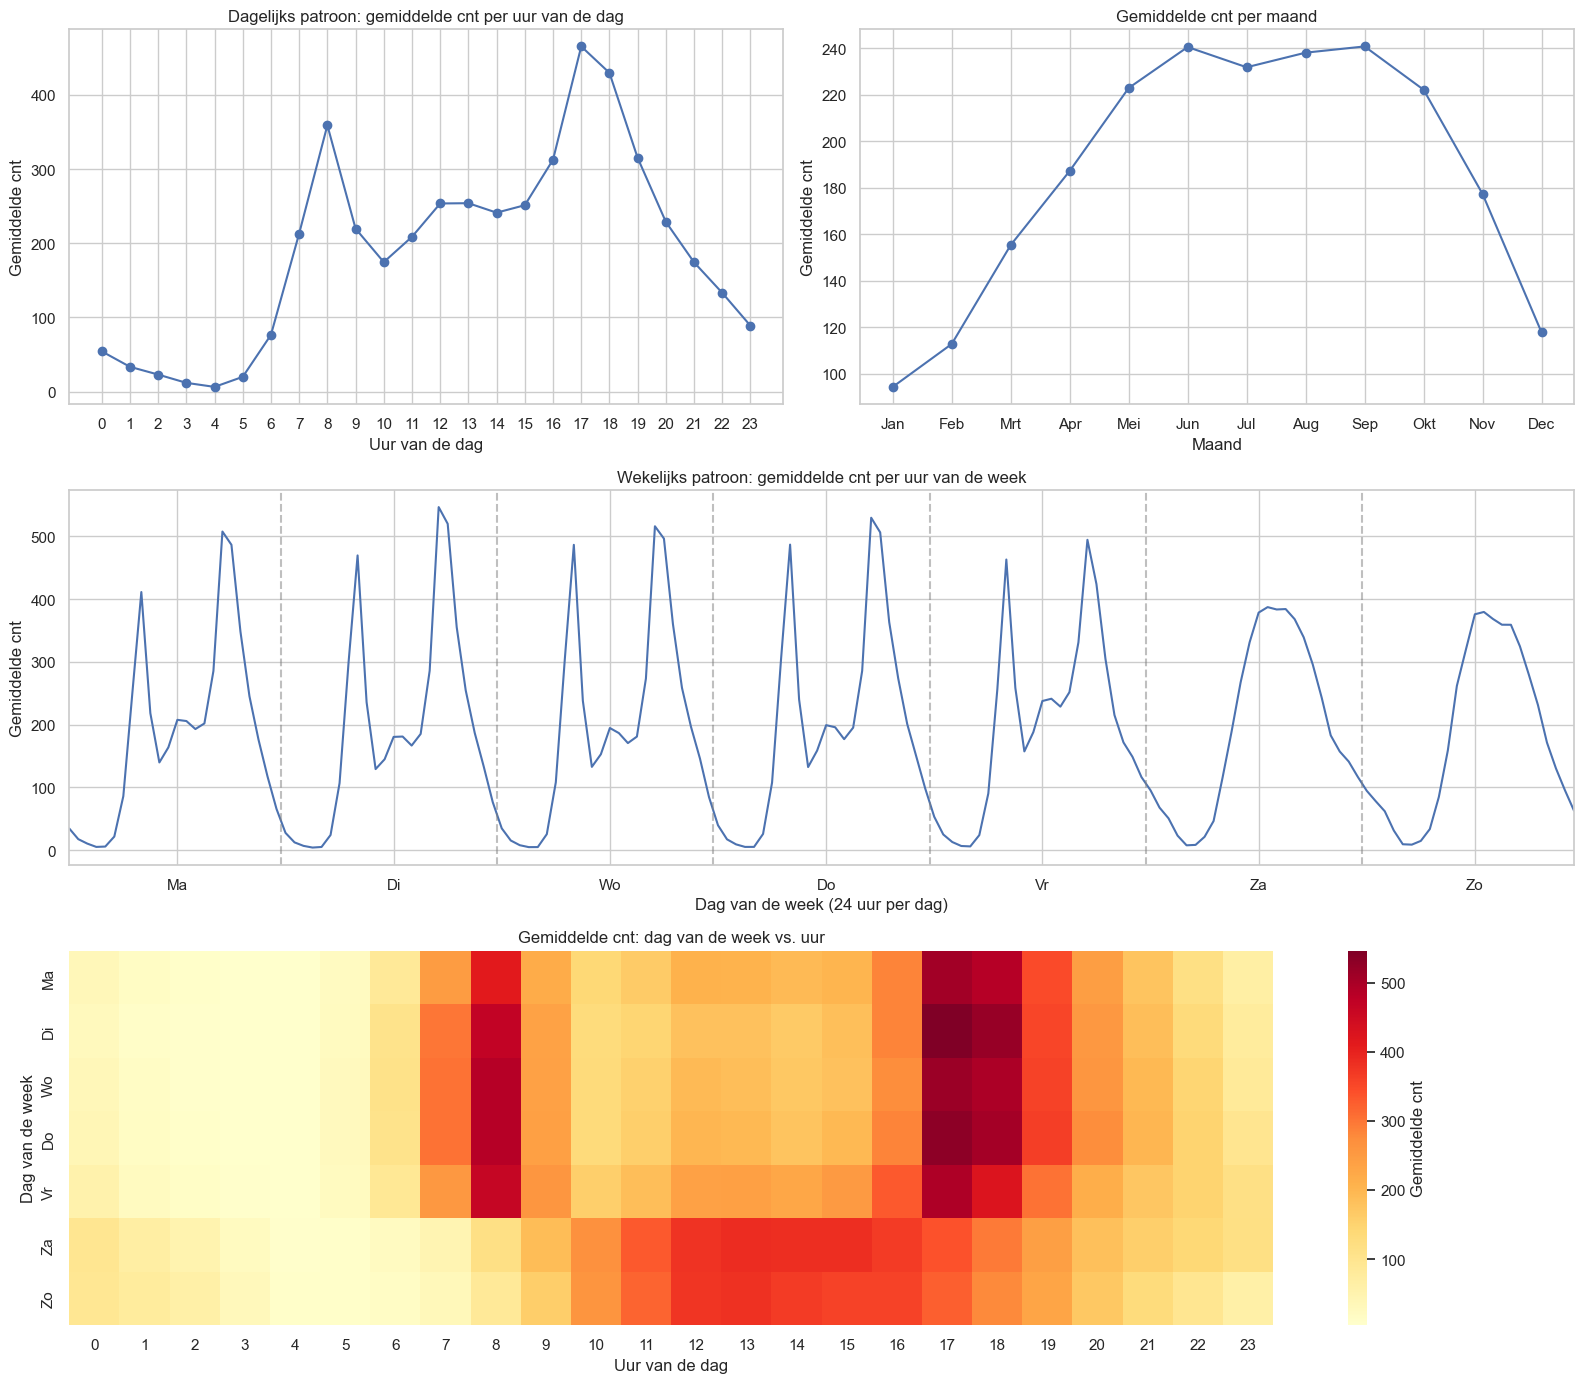

In [105]:
class CyclischePatronenAnalyse:
    """Visualiseert cyclische patronen (dag, week, maand) in een tijdreeks."""

    DAGEN = ["Ma", "Di", "Wo", "Do", "Vr", "Za", "Zo"]
    MAANDEN = ["Jan", "Feb", "Mrt", "Apr", "Mei", "Jun",
               "Jul", "Aug", "Sep", "Okt", "Nov", "Dec"]

    def __init__(self, df: pd.DataFrame, datum_kolom: str = "date_hour",
                 doel_kolom: str = "cnt"):
        self.doel = doel_kolom
        self.df = df.copy()
        self.df[datum_kolom] = pd.to_datetime(self.df[datum_kolom])
        self.df = self.df.sort_values(datum_kolom)

        # Tijdfeatures afleiden uit de datumkolom
        d = self.df[datum_kolom].dt
        self.df["uur"] = d.hour
        self.df["weekdag"] = d.dayofweek  # 0 = maandag
        self.df["maand"] = d.month
        self.df["jaar"] = d.year
        self.df["uur_van_week"] = self.df["weekdag"] * 24 + self.df["uur"]  # 0..167

        sns.set_theme(style="whitegrid")

    # ---------- 1. Dagelijks patroon: gemiddelde per uur van de dag ----------
    def plot_uurpatroon(self, ax=None):
        ax = ax or plt.subplots(figsize=(10, 5))[1]
        gem = self.df.groupby("uur")[self.doel].mean()
        ax.plot(gem.index, gem.values, marker="o")
        ax.set(title=f"Dagelijks patroon: gemiddelde {self.doel} per uur van de dag",
               xlabel="Uur van de dag", ylabel=f"Gemiddelde {self.doel}",
               xticks=range(24))
        return ax

    # ---------- 2. Wekelijks patroon: gemiddelde per uur van de week ----------
    def plot_weekpatroon(self, ax=None):
        ax = ax or plt.subplots(figsize=(14, 5))[1]
        gem = self.df.groupby("uur_van_week")[self.doel].mean()
        ax.plot(gem.index, gem.values)

        # Dagscheiding en daglabels in het midden van elke dag
        for grens in range(24, 168, 24):
            ax.axvline(grens - 0.5, color="grey", linestyle="--", alpha=0.5)
        ax.set_xticks([i * 24 + 12 for i in range(7)])
        ax.set_xticklabels(self.DAGEN)
        ax.set(title=f"Wekelijks patroon: gemiddelde {self.doel} per uur van de week",
               xlabel="Dag van de week (24 uur per dag)",
               ylabel=f"Gemiddelde {self.doel}", xlim=(0, 167))
        return ax

    # ---------- 3. Heatmap weekdag x uur ----------
    def plot_heatmap(self, ax=None):
        ax = ax or plt.subplots(figsize=(12, 5))[1]
        pivot = self.df.pivot_table(index="weekdag", columns="uur",
                                    values=self.doel, aggfunc="mean")
        pivot.index = [self.DAGEN[i] for i in pivot.index]
        sns.heatmap(pivot, cmap="YlOrRd", cbar_kws={"label": f"Gemiddelde {self.doel}"}, ax=ax)
        ax.set(title=f"Gemiddelde {self.doel}: dag van de week vs. uur",
               xlabel="Uur van de dag", ylabel="Dag van de week")
        return ax

    # ---------- 4. Gemiddelde per maand ----------
    def plot_maandpatroon(self, ax=None):
        ax = ax or plt.subplots(figsize=(10, 5))[1]
        gem = self.df.groupby("maand")[self.doel].mean()
        ax.plot(gem.index, gem.values, marker="o")
        ax.set(title=f"Gemiddelde {self.doel} per maand",
               xlabel="Maand", ylabel=f"Gemiddelde {self.doel}",
               xticks=range(1, 13))
        ax.set_xticklabels(self.MAANDEN)
        return ax

    # ---------- Alles in één figuur ----------
    def plot_alles(self):
        fig = plt.figure(figsize=(16, 14))
        gs = fig.add_gridspec(3, 2)
        self.plot_uurpatroon(fig.add_subplot(gs[0, 0]))
        self.plot_maandpatroon(fig.add_subplot(gs[0, 1]))
        self.plot_weekpatroon(fig.add_subplot(gs[1, :]))
        self.plot_heatmap(fig.add_subplot(gs[2, :]))
        fig.tight_layout()
        return fig


train_clean = train_clean.reset_index()
analyse = CyclischePatronenAnalyse(train_clean, datum_kolom="date_hour", doel_kolom="cnt")
analyse.plot_alles()
plt.show()

In [106]:
# AI gebruik
log_ai(
    titel="Python-grafieken voor cyclische patronen",
    model="Claude Sonnet 5.5",
    link="https://claude.ai/share/0f17ab01-5376-416e-934b-414bb0120f43",
    waar="2.3, cel 2"
)

## 2.4 Relaties tussen de variabelen en de target

,pearson,spearman,Verschil
cnt,1.000000,1.000000,0.000000
atemp,0.404820,0.429585,0.024764
temp,0.409245,0.429074,0.019829
jaar,0.266739,0.222643,0.044096
maand,0.140023,0.147818,0.007795
windspeed,0.097006,0.129959,0.032953
weekdag,-0.002969,0.009866,0.012835
dag,0.010302,0.008202,0.002101
weekend,-0.015812,-0.007685,0.008127
holiday,-0.026586,-0.023998,0.002588


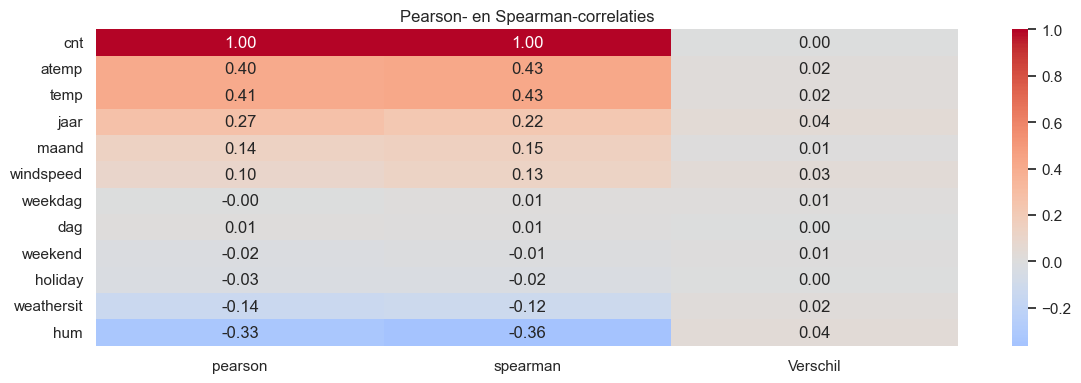

In [107]:
numeriek = train_clean.select_dtypes(include="number")

vergelijking = pd.DataFrame({
    "pearson": numeriek.corr(method="pearson")[TARGET],
    "spearman": numeriek.corr(method="spearman")[TARGET]
}).sort_values("spearman", ascending=False)

vergelijking["Verschil"] = abs(vergelijking["pearson"] - vergelijking["spearman"])

display(vergelijking)

sns.heatmap(vergelijking, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Pearson- en Spearman-correlaties")
plt.tight_layout()
plt.show()

## 2.5 Relaties tussen features

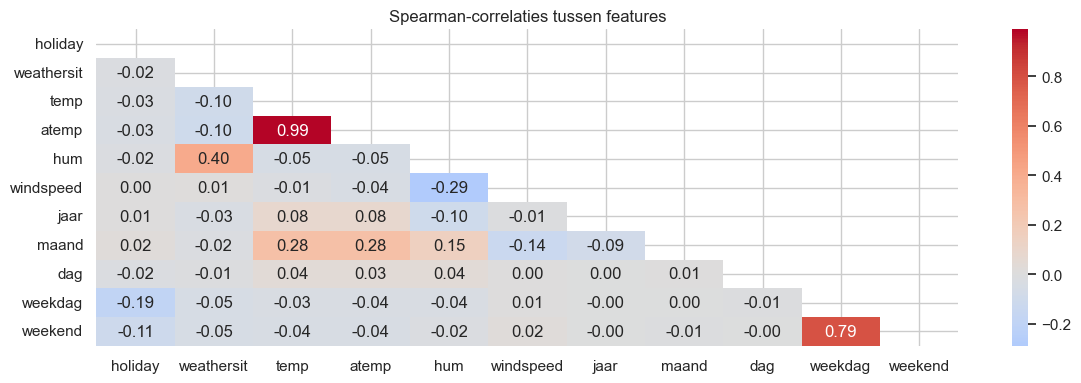

In [108]:
features = train_clean.select_dtypes(include="number").drop(columns=TARGET)

correlaties = features.corr(method="spearman")

sns.heatmap(correlaties, annot=True, fmt=".2f", cmap="coolwarm", center=0, mask= np.triu(np.ones_like(correlaties, dtype=bool)))
plt.title("Spearman-correlaties tussen features")
plt.tight_layout()
plt.show()

## 2.5 Belangrijkste bevindingen van de EDA

### Datakwaliteit

- Er ontbreken geen waarden en er zijn geen dubbele rijen.
- `date_hour` is omgezet naar een datetime-kolom.
- `windspeed`, `holiday` en `cnt` hebben de meeste outliers.

### Patronen in de data

- **Jaarlijks patroon:** de grafiek in 2.3 laat een duidelijk jaarlijks verloop zien.
- **Heatmap & lijngrafiek (2.3):** doordeweeks is het het drukst tijdens de spits. In het weekend loopt de drukte door en is het in de middag het drukst.
- **Lijngrafiek (2.3):** In de zomer is het ook drukker dan in de winter.

### Correlaties

- **Target:** de gevoelstemperatuur heeft de hoogste correlatie met `cnt`.
- **Onderling gerelateerde features:** weekdag en weekend, en temperatuur en gevoelstemperatuur.

<a id="h3"></a>
# 3. Opdracht 2: Time series feature engineering

[Terug naar boven](#top)

## 3.1 Trend

De **trend** is de algemene richting van de variabele over de tijd. Deze kan worden berekend met een rolling window.

#### Toegevoegde features:
Om de trend in kaart te brengen:
- `rolling_mean_24` bevat de plaatselijk gemiddelde waarde van atemp.
- `rolling_std_24` bevat de plaatselijk standaard deviatie van atemp.
- `rolling_min_24` bevat de plaatselijk minimale waarde van atemp.
- `rolling_max_24` bevat de plaatselijk maximale waarde van atemp.

Om de seizoenspatronen in kaart te brengen:
- `Januari - November` zijn boolean kolommen per maand zodat het model een gewicht kan geven aan indivuele maanden.

Hieronder hebben wij een functie die de trend, de seasonal component van de eerste twee weken en de residual laat zien.

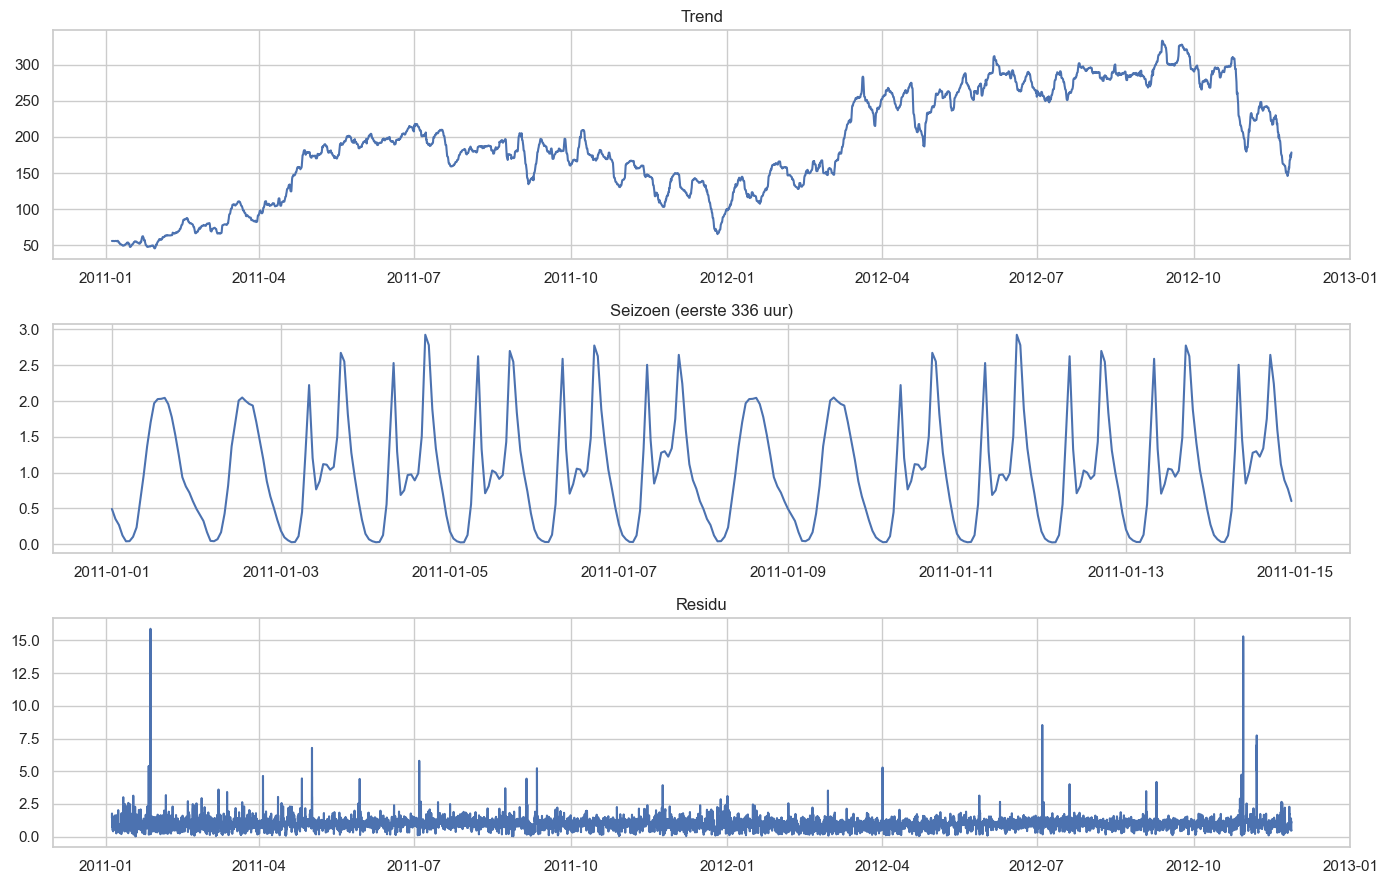

In [ ]:
def plot_decompositie(df, datum_kolom="date_hour", doel="cnt", periode=24,
                      model="additive"):
    reeks = (df.set_index(datum_kolom)[doel]
               .sort_index()
               .asfreq("h")
               .interpolate())        # gaten opvullen, anders werkt de decompositie niet

    res = seasonal_decompose(reeks, model=model, period=periode)

    fig, axes = plt.subplots(3, 1, figsize=(14, 9))
    axes[0].plot(res.trend)
    axes[0].set_title("Trend")

    eerste = res.seasonal.iloc[:2 * periode]
    axes[1].plot(eerste)
    axes[1].set_title(f"Seizoen (eerste {2 * periode} uur)")

    axes[2].plot(res.resid)
    axes[2].set_title("Residu")
    fig.tight_layout()
    return res

res = plot_decompositie(train_clean, periode=168, model="multiplicative")

Vervolgens voegen wij features toe, omdat de fietsverhuur afhankelijk is van de tijden en patronen eromheen.

In [129]:
#trend toevoegen als features
target = "atemp"
shifted = train_clean[target].shift(1)

# Voeg rolling window-statistieken toe aan train (over de afgelopen 24 metingen)
train_clean["rolling_mean_24"] = shifted.rolling(window=24, min_periods=1).mean().bfill()
train_clean["rolling_std_24"] = shifted.rolling(window=24, min_periods=2).std().bfill()
train_clean["rolling_min_24"] = shifted.rolling(window=24, min_periods=1).min().bfill()
train_clean["rolling_max_24"] = shifted.rolling(window=24, min_periods=1).max().bfill()

# Bereken op test met de laatste 'window' rijen van train als aanloop
gecombineerd = pd.concat([train_clean[[target]].tail(24), test_clean[[target]]], ignore_index=True)
test_rolling_mean = gecombineerd[target].shift(1).rolling(window=24, min_periods=1).mean().bfill()
test_rolling_std = gecombineerd[target].shift(1).rolling(window=24, min_periods=2).std().bfill()
test_rolling_min = gecombineerd[target].shift(1).rolling(window=24, min_periods=1).min().bfill()
test_rolling_max = gecombineerd[target].shift(1).rolling(window=24, min_periods=1).max().bfill()

# Gebruik .values zodat de oorspronkelijke index van 'test' intact blijft
test_clean['rolling_mean_24'] = test_rolling_mean.iloc[24:].values
test_clean['rolling_std_24'] = test_rolling_std.iloc[24:].values
test_clean['rolling_min_24'] = test_rolling_min.iloc[24:].values
test_clean['rolling_max_24'] = test_rolling_max.iloc[24:].values

display(train_clean.head())

,date_hour,holiday,weathersit,temp,atemp,hum,windspeed,cnt,jaar,maand,dag,weekdag,weekend,rolling_mean_24,rolling_std_24,rolling_min_24,rolling_max_24
0,2011-01-01 00:00:00,0,1,0.24,0.2879,0.81,0.0,16,2011,1,1,5,1,0.287900,0.010748,0.2879,0.2879
1,2011-01-01 01:00:00,0,1,0.22,0.2727,0.80,0.0,40,2011,1,1,5,1,0.287900,0.010748,0.2879,0.2879
2,2011-01-01 02:00:00,0,1,0.22,0.2727,0.80,0.0,32,2011,1,1,5,1,0.280300,0.010748,0.2727,0.2879
3,2011-01-01 03:00:00,0,1,0.24,0.2879,0.75,0.0,13,2011,1,1,5,1,0.277767,0.008776,0.2727,0.2879
4,2011-01-01 04:00:00,0,1,0.24,0.2879,0.75,0.0,1,2011,1,1,5,1,0.280300,0.008776,0.2727,0.2879


In [130]:
# AI gebruik
log_ai(
    titel="Features voor van de trend en maanden",
    model="Gemini Hydrogen",
    link="https://share.gemini.google/4Xqej8l7YTg1",
    waar="4.1, cel 1"
)

## 3.2 Seizoenspatronen met Fourier-analyse
Een seizoenspatroon is een regelmatig terugkerend patroon met een vaste periode. Met de Fourier-transformatie (FFT) ontleed je de reeks en zie je welke de frequenties van deze herhalende patronen.

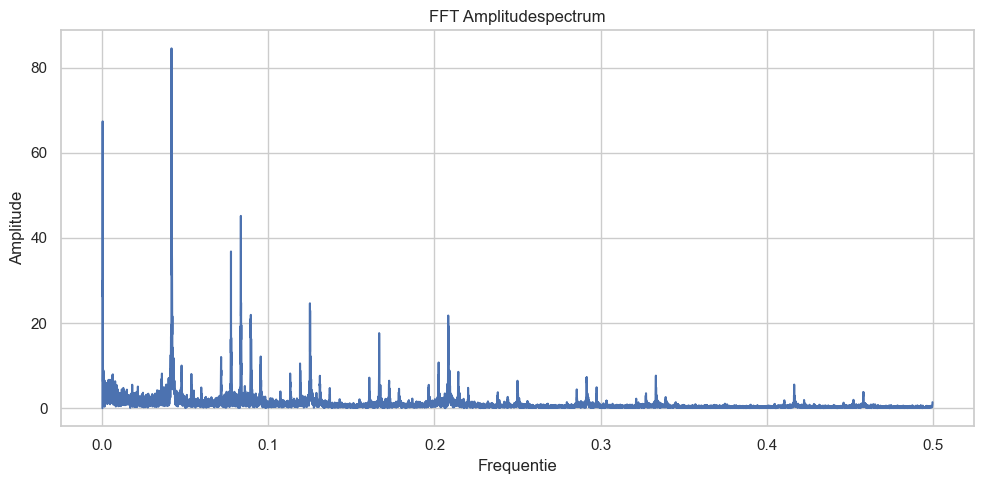

In [ ]:
# 1. Haal het signaal op en verwijder de DC-offset (gemiddelde)
signaal = train_clean['cnt'].to_numpy()
signaal = signaal - np.mean(signaal)

# 2. Bepaal het aantal samples en de tijdstap (dt)
n = len(signaal)
dt = train_clean['date_hour'].iloc[1] - train_clean['date_hour'].iloc[0]  # Of direct: dt = 1 / fs
dt = (train_clean['date_hour'].iloc[1] - train_clean['date_hour'].iloc[0]) / pd.Timedelta(hours=1)

# 3. Voer de FFT uit (rfft geeft alleen positieve frequenties voor reële data)
fft_waarden = np.fft.rfft(signaal)
frequenties = np.fft.rfftfreq(n, d=dt)

# 4. Bereken de genormaliseerde amplitude en sla op in een nieuw DataFrame
amplitude = (2 / n) * np.abs(fft_waarden)
amplitude[0] = amplitude[0] / 2  # DC-component niet verdubbelen

fft_df = pd.DataFrame({
    'frequentie_hz': frequenties,
    'amplitude': amplitude
})

# 5. plot de frequentie chard
plt.figure(figsize=(10, 5))
plt.plot(fft_df['frequentie_hz'], fft_df['amplitude'])
plt.title('FFT Amplitudespectrum')
plt.xlabel('Frequentie')
plt.ylabel('Amplitude')
plt.tight_layout()
plt.show()

In [ ]:
# maanden omzetten naar dummys als feature voor seizoenspatronen
maanden = {
    1: "Januari", 2: "Februari", 3: "Maart", 4: "April",
    5: "Mei", 6: "Juni", 7: "Juli", 8: "Augustus",
    9: "September", 10: "Oktober", 11: "November"
}

for df in [train_clean, test_clean]:
    for maand_nr, maand_naam in maanden.items():
            df[maand_naam] = (df["maand"] == maand_nr).astype(int)

    df.drop(columns=["maand"], inplace=True)

# uren omzetten naar dummys als feature voor seizoenspatronen
def encode_hours(df, column):
    df = df.copy()

    # Controleren of de kolom het juiste datatype heeft
    if not pd.api.types.is_datetime64_any_dtype(df[column]):
        raise TypeError(f"Kolom '{column}' moet een datetime datatype hebben.")

    # Uren uit de datetime-kolom halen
    hours = df[column].dt.hour

    # Dummyvariabelen aanmaken en het eerste uur weglaten
    hour_dummies = pd.get_dummies(
        hours,
        prefix="uur",
        drop_first=True,
        dtype=int
    )

    # Dummyvariabelen toevoegen aan het dataframe
    df = pd.concat([df, hour_dummies], axis=1)

    return df
train_clean = encode_hours(train_clean, "date_hour")
display(train_clean.columns, train_clean.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16637 entries, 0 to 16636
Data columns (total 50 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   date_hour        16637 non-null  datetime64[ns]
 1   holiday          16637 non-null  int64         
 2   weathersit       16637 non-null  int64         
 3   temp             16637 non-null  float64       
 4   atemp            16637 non-null  float64       
 5   hum              16637 non-null  float64       
 6   windspeed        16637 non-null  float64       
 7   cnt              16637 non-null  int64         
 8   jaar             16637 non-null  int32         
 9   dag              16637 non-null  int32         
 10  weekdag          16637 non-null  int32         
 11  weekend          16637 non-null  int64         
 12  rolling_mean_24  16637 non-null  float64       
 13  rolling_std_24   16637 non-null  float64       
 14  rolling_min_24   16637 non-null  float

Index(['date_hour', 'holiday', 'weathersit', 'temp', 'atemp', 'hum',
       'windspeed', 'cnt', 'jaar', 'dag', 'weekdag', 'weekend',
       'rolling_mean_24', 'rolling_std_24', 'rolling_min_24', 'rolling_max_24',
       'Januari', 'Februari', 'Maart', 'April', 'Mei', 'Juni', 'Juli',
       'Augustus', 'September', 'Oktober', 'November', 'uur_1', 'uur_2',
       'uur_3', 'uur_4', 'uur_5', 'uur_6', 'uur_7', 'uur_8', 'uur_9', 'uur_10',
       'uur_11', 'uur_12', 'uur_13', 'uur_14', 'uur_15', 'uur_16', 'uur_17',
       'uur_18', 'uur_19', 'uur_20', 'uur_21', 'uur_22', 'uur_23'],
      dtype='object')

None

In [ ]:
log_ai(
    titel="Features voor van het uur van de dag",
    model="GPT",
    link="https://chatgpt.com/share/6b082032-8330-83ed-b0e9-0f268682901e",
    waar="4.1, cel 4"
)